# Lab Day 10: Finetune Qwen3-VL-4B (LoRA) để định vị hư hại mặt đường
Đọc `README.md` và `GUIDE.md` trước. Notebook này chỉ là **khung**: bạn tự viết mã theo pseudo code trong GUIDE.

## 0. Môi trường (Colab T4)

Runtime → Change runtime type → **T4 GPU** → Save. Phần này: lấy repo, cài thư viện, nạp Kaggle Secrets,
mount Drive (lưu adapter/checkpoint), rồi chạy `pytest` để chắc công cụ của đề chạy đúng.

In [1]:
# Runtime → Change runtime type → T4 GPU
!nvidia-smi -L

# Mở notebook từ GitHub thì Colab đứng ở /content, chưa có scripts/ → clone repo và cd vào.
import os
REPO_URL = "https://github.com/SxAinsworth/K4-Track-4-Day10-VisionLanguageModel.git"
REPO_DIR = "/content/K4-Track-4-Day10-VisionLanguageModel"
if not os.path.exists("scripts/score.py"):
    if not os.path.exists(REPO_DIR):
        !git clone -q {REPO_URL} {REPO_DIR}
    %cd {REPO_DIR}
print("cwd:", os.getcwd())

GPU 0: Tesla T4 (UUID: GPU-5a85d8da-7e62-a248-6bff-f4b5ce21086c)
/content/K4-Track-4-Day10-VisionLanguageModel
cwd: /content/K4-Track-4-Day10-VisionLanguageModel


In [2]:
!pip -q install -r requirements-colab.txt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 65.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 24.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 889.0/889.0 kB 32.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 15.2 MB/s eta 0:00:00


In [3]:
# Kaggle (tuỳ chọn): nếu có Colab Secrets KAGGLE_USERNAME / KAGGLE_KEY thì dùng Kaggle CLI.
# Không có cũng được: dataset công khai, bước 1 sẽ tải ẩn danh bằng kagglehub. KHÔNG viết khoá vào notebook.
import os
USE_KAGGLE_CLI = False
try:
    from google.colab import userdata
    os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
    os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')
    USE_KAGGLE_CLI = True
    print("Kaggle user:", os.environ['KAGGLE_USERNAME'])
except Exception as e:
    print(f"Không dùng Kaggle Secrets ({type(e).__name__}) → sẽ tải ẩn danh bằng kagglehub.")

Không dùng Kaggle Secrets (SecretNotFoundError) → sẽ tải ẩn danh bằng kagglehub.


In [4]:
# Mount Google Drive để sao lưu adapter LoRA / projector / predictions sau mỗi lần chạy
# (session Colab miễn phí có thể bị ngắt giữa chừng).
from pathlib import Path
from google.colab import drive
drive.mount("/content/drive")
DRIVE_DIR = Path("/content/drive/MyDrive/lab_day10_v2")   # v2: kết quả cũ trong lab_day10/ chạy với ViT 4-bit (sai)
DRIVE_DIR.mkdir(parents=True, exist_ok=True)
print("Sao lưu vào:", DRIVE_DIR)

import shutil

def backup(path):
    """Chép file/thư mục (đường dẫn tương đối trong repo) sang DRIVE_DIR."""
    src, dst = Path(path), DRIVE_DIR / path
    dst.parent.mkdir(parents=True, exist_ok=True)
    if src.is_dir():
        shutil.copytree(src, dst, dirs_exist_ok=True)
    elif src.exists():
        shutil.copy2(src, dst)

def restore(path):
    """Local chưa có mà Drive có (runtime mới sau khi bị ngắt) → chép về. Trả True nếu đã chép."""
    src, dst = DRIVE_DIR / path, Path(path)
    if dst.exists() or not src.exists():
        return False
    dst.parent.mkdir(parents=True, exist_ok=True)
    if src.is_dir():
        shutil.copytree(src, dst)
    else:
        shutil.copy2(src, dst)
    print("restore từ Drive:", path)
    return True

Mounted at /content/drive
Sao lưu vào: /content/drive/MyDrive/lab_day10_v2


In [5]:
# Kiểm tra công cụ của đề. Kỳ vọng: 68 passed, 1 skipped (test dữ liệu thật bị bỏ qua khi chưa tải dataset).
!python -m pytest -q

...........................s.........................................    [100%]
68 passed, 1 skipped in 0.50s


## 1. Dữ liệu: tải và chia split

In [6]:
# Tải dataset và chia split theo phiên quay (cố định, ai chạy cũng ra cùng kết quả).
# Bỏ qua nếu đã có data/ (chạy lại notebook mà runtime còn giữ ổ đĩa).
import os
if os.path.exists("data/splits/meta.json"):
    print("Đã có data/splits/meta.json, bỏ qua bước tải.")
elif USE_KAGGLE_CLI:
    !python scripts/prepare_data.py --kaggle
else:
    # Dataset công khai (MIT): kagglehub tải được không cần đăng nhập
    !pip -q install kagglehub
    import kagglehub
    KAGGLE_SLUG = "lorenzoarcioni/road-damage-dataset-potholes-cracks-and-manholes"
    src_dir = kagglehub.dataset_download(KAGGLE_SLUG)
    print("Đã tải về:", src_dir)
    !python scripts/prepare_data.py --source "{src_dir}"

100%|██████████| 185M/185M [00:01<00:00, 141MB/s]

Extracting files...


Đã tải về: /root/.cache/kagglehub/datasets/lorenzoarcioni/road-damage-dataset-potholes-cracks-and-manholes/versions/4
dataset_version : d10-21e4070301
  train  1422 ảnh  boxes={'pothole': 1074, 'crack': 1750, 'manhole': 691}
  val     276 ảnh  boxes={'pothole': 66, 'crack': 470, 'manhole': 103}
  test    311 ảnh  boxes={'pothole': 121, 'crack': 299, 'manhole': 163}


In [7]:
# Thống kê từng split + kiểm tra rò rỉ phiên quay (số liệu cho câu 6 của REPORT).
import json
from collections import Counter
from scripts.labcommon import CLASSES, read_jsonl

SPLITS = ("train", "val", "test")
data = {s: read_jsonl(f"data/splits/{s}.jsonl") for s in SPLITS}
meta = json.load(open("data/splits/meta.json", encoding="utf-8"))
DATASET_VERSION = meta["dataset_version"]
print("dataset_version:", DATASET_VERSION)
assert DATASET_VERSION.startswith("d10-"), DATASET_VERSION

# Bảng chuẩn của đề (README mục 3): ảnh, pothole, crack, manhole
EXPECTED = {"train": (1422, 1074, 1750, 691), "val": (276, 66, 470, 103), "test": (311, 121, 299, 163)}
print(f"{'split':6s} {'ảnh':>5s} {'sessions':>8s} " + " ".join(f"{c:>8s}" for c in CLASSES) + f" {'box/ảnh':>8s} {'ảnh rỗng':>8s}")
for s in SPLITS:
    rows = data[s]
    box = Counter(o["label"] for r in rows for o in r["objects"])
    n_box = sum(box.values())
    n_empty = sum(1 for r in rows if not r["objects"])
    n_sess = len({r["session"] for r in rows})
    print(f"{s:6s} {len(rows):5d} {n_sess:8d} " + " ".join(f"{box[c]:8d}" for c in CLASSES)
          + f" {n_box / len(rows):8.2f} {n_empty:8d}")
    got = (len(rows), *(box[c] for c in CLASSES))
    assert got == EXPECTED[s], f"{s}: {got} != {EXPECTED[s]}"

# Không session nào nằm ở 2 split
sess = {s: {r["session"] for r in data[s]} for s in SPLITS}
for a, b in (("train", "val"), ("train", "test"), ("val", "test")):
    inter = sess[a] & sess[b]
    assert not inter, f"Rò rỉ phiên quay {a}/{b}: {sorted(inter)[:5]}"
print("OK: số ảnh/box khớp bảng của đề; không session nào xuất hiện ở hai split.")

# Kích thước box: diện tích tương đối (w*h) theo lớp, trên train (dùng cho câu 9)
import statistics
for c in CLASSES:
    areas = [o["yolo"][2] * o["yolo"][3] for r in data["train"] for o in r["objects"] if o["label"] == c]
    print(f"  {c:8s} diện tích trung vị = {100 * statistics.median(areas):.2f}% khung hình")

dataset_version: d10-21e4070301
split    ảnh sessions  pothole    crack  manhole  box/ảnh ảnh rỗng
train   1422       13     1074     1750      691     2.47        0
val      276        2       66      470      103     2.32        0
test     311        3      121      299      163     1.87        0
OK: số ảnh/box khớp bảng của đề; không session nào xuất hiện ở hai split.
  pothole  diện tích trung vị = 0.38% khung hình
  crack    diện tích trung vị = 1.35% khung hình
  manhole  diện tích trung vị = 0.39% khung hình


In [8]:
# Minh hoạ vì sao KHÔNG chia ngẫu nhiên: nếu chia theo ảnh (cùng tỉ lệ ~15% test),
# bao nhiêu ảnh test có "anh em" cùng phiên quay nằm trong train? (số liệu cho câu 6)
import random
all_rows = [r for s in SPLITS for r in data[s]]
rng = random.Random(0)
shuffled = all_rows[:]
rng.shuffle(shuffled)
n_test = len(data["test"])
rand_test, rand_train = shuffled[:n_test], shuffled[n_test:]
train_sess = {r["session"] for r in rand_train}
leaked = sum(1 for r in rand_test if r["session"] in train_sess)
print(f"Chia ngẫu nhiên: {leaked}/{n_test} ảnh test ({100 * leaked / n_test:.1f}%) có cùng phiên quay với ảnh train.")
print(f"Chia theo phiên (prepare_data.py): 0/{n_test} ảnh test.")
print("Số phiên quay:", len({r['session'] for r in all_rows}), "| ảnh/phiên trung bình:",
      round(len(all_rows) / len({r['session'] for r in all_rows}), 1))

Chia ngẫu nhiên: 311/311 ảnh test (100.0%) có cùng phiên quay với ảnh train.
Chia theo phiên (prepare_data.py): 0/311 ảnh test.
Số phiên quay: 18 | ảnh/phiên trung bình: 111.6


Vẽ 6 ảnh train kèm box gốc (YOLO → pixel) để chắc hiểu nhãn. Ảnh được lưu vào `report/figures/data_samples.png`.

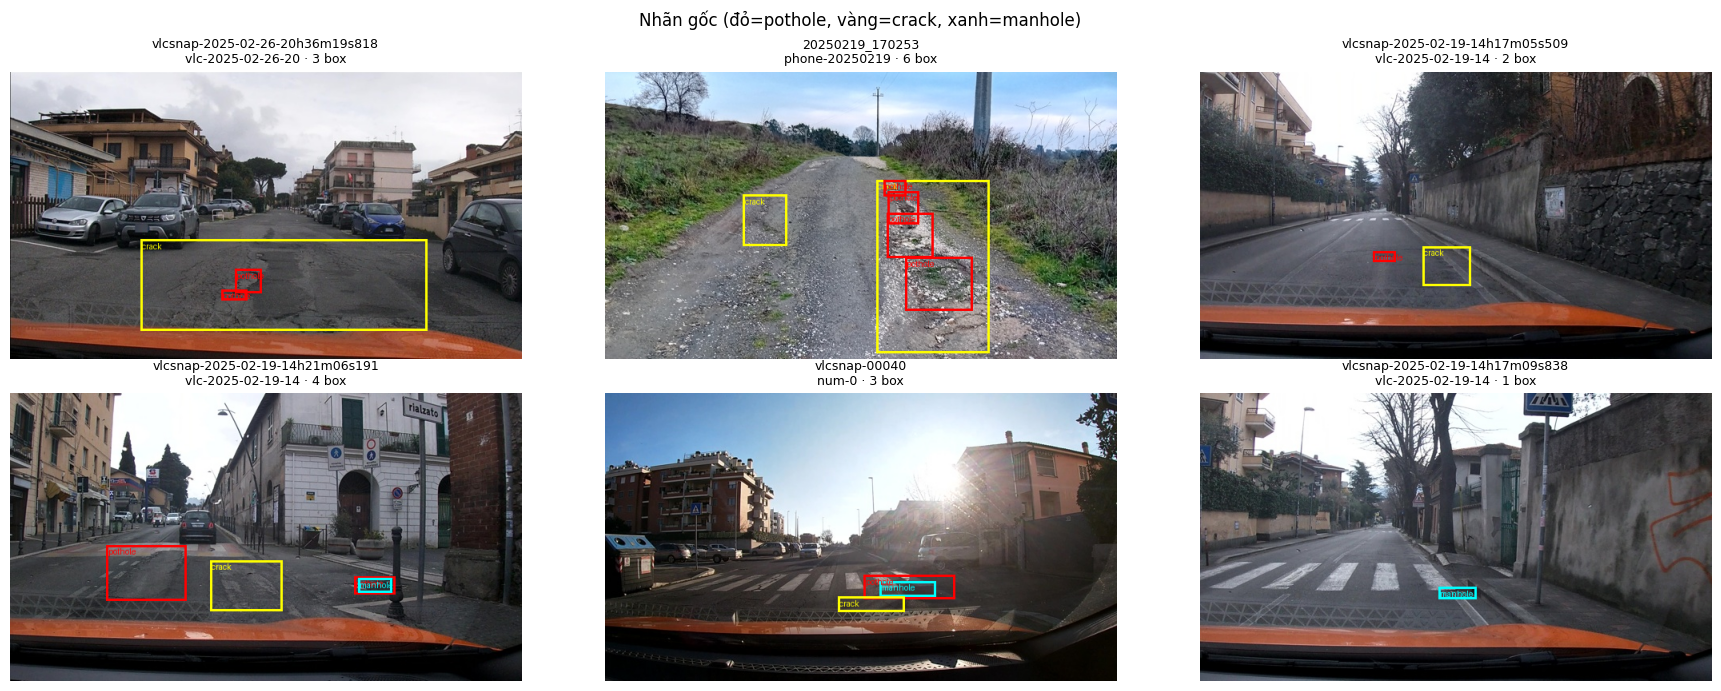

Kích thước ảnh (W, H): Counter({(640, 360): 2009})


In [9]:
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image, ImageDraw

COLORS = {"pothole": "red", "crack": "yellow", "manhole": "cyan"}

def draw_yolo(img, objects, width=3):
    """Vẽ box YOLO (xc, yc, w, h chuẩn hoá [0,1]) lên bản sao của ảnh."""
    img = img.copy()
    d = ImageDraw.Draw(img)
    W, H = img.size
    for o in objects:
        xc, yc, w, h = o["yolo"]
        box = ((xc - w / 2) * W, (yc - h / 2) * H, (xc + w / 2) * W, (yc + h / 2) * H)
        d.rectangle(box, outline=COLORS[o["label"]], width=width)
        d.text((box[0] + 2, box[1] + 2), o["label"], fill=COLORS[o["label"]])
    return img

rng = random.Random(10)
# Lấy mẫu có đủ cả 3 lớp: 2 ảnh có pothole, 2 có crack, 2 có manhole
samples = []
for c in CLASSES:
    pool = [r for r in data["train"] if any(o["label"] == c for o in r["objects"]) and r not in samples]
    samples += rng.sample(pool, 2)

fig, axes = plt.subplots(2, 3, figsize=(18, 7))
for ax, r in zip(axes.flat, samples):
    img = Image.open(Path("data") / r["image_path"]).convert("RGB")
    ax.imshow(draw_yolo(img, r["objects"]))
    ax.set_title(f"{r['image_id']}\n{r['session']} · {len(r['objects'])} box", fontsize=9)
    ax.axis("off")
fig.suptitle("Nhãn gốc (đỏ=pothole, vàng=crack, xanh=manhole)")
plt.tight_layout()
Path("report/figures").mkdir(parents=True, exist_ok=True)
fig.savefig("report/figures/data_samples.png", dpi=80, bbox_inches="tight")
backup("report/figures/data_samples.png")
plt.show()
print("Kích thước ảnh (W, H):", Counter((r["width"], r["height"]) for r in all_rows))

## 2. Nhãn: YOLO → JSON thang 0–1000

In [10]:
import json

def yolo_to_box(label, yolo):
    """YOLO (xc, yc, w, h chuẩn hoá [0,1]) → {"label", "bbox_2d": [x1,y1,x2,y2]} nguyên trên thang 0–1000."""
    xc, yc, w, h = yolo
    clamp = lambda v: int(round(max(0.0, min(1000.0, v * 1000))))
    x1, y1 = clamp(xc - w / 2), clamp(yc - h / 2)
    x2, y2 = clamp(xc + w / 2), clamp(yc + h / 2)
    # Box rất nhỏ có thể bị làm tròn thành suy biến → parse_output của trọng tài sẽ coi là JSON hỏng.
    if x2 <= x1:
        x1, x2 = (x1, x1 + 1) if x1 < 1000 else (999, 1000)
    if y2 <= y1:
        y1, y2 = (y1, y1 + 1) if y1 < 1000 else (999, 1000)
    return {"label": label, "bbox_2d": [x1, y1, x2, y2]}

def objects_to_answer(objects):
    """Danh sách object → chuỗi JSON đáp án. Sắp theo (y1, x1): trên→dưới, trái→phải để model học một thứ tự ổn định."""
    boxes = [yolo_to_box(o["label"], o["yolo"]) for o in objects]
    boxes.sort(key=lambda b: (b["bbox_2d"][1], b["bbox_2d"][0]))
    return json.dumps(boxes, separators=(",", ":"))   # "[]" nếu ảnh không có hư hại

PROMPT = (
    "Locate road damage in this image. "
    "Detect only objects of classes: pothole, crack, manhole. "
    "Output a JSON list of objects with label and bbox_2d coordinates "
    "normalized on a 0-1000 scale: "
    '[{"label": "...", "bbox_2d": [x1, y1, x2, y2]}]. '
    "If no damage is found, output []."
)

r0 = data["train"][0]
print(r0["image_id"], "→", objects_to_answer(r0["objects"]))
print("ảnh rỗng →", objects_to_answer([]))

20250216_164325 → [{"label":"crack","bbox_2d":[430,467,583,506]},{"label":"pothole","bbox_2d":[361,475,414,522]},{"label":"manhole","bbox_2d":[317,481,616,625]},{"label":"pothole","bbox_2d":[583,500,627,614]},{"label":"crack","bbox_2d":[580,508,655,614]},{"label":"pothole","bbox_2d":[259,517,311,572]},{"label":"crack","bbox_2d":[397,628,447,717]},{"label":"crack","bbox_2d":[339,683,398,808]},{"label":"crack","bbox_2d":[158,789,361,994]}]
ảnh rỗng → []


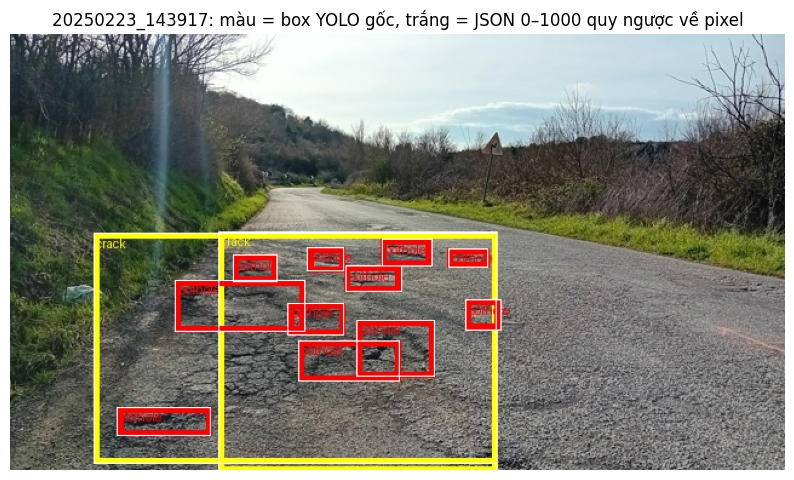

Sai số quy đổi lớn nhất: 0.32 px


In [11]:
# Kiểm tra 1: JSON 0–1000 → pixel, vẽ chồng lên box gốc (YOLO). Hai box phải trùng nhau.
def answer_to_pixels(answer, W, H):
    return [(b["label"], [b["bbox_2d"][0] * W / 1000, b["bbox_2d"][1] * H / 1000,
                          b["bbox_2d"][2] * W / 1000, b["bbox_2d"][3] * H / 1000]) for b in json.loads(answer)]

r = max(data["train"], key=lambda r: len(r["objects"]))      # ảnh nhiều box nhất
img = Image.open(Path("data") / r["image_path"]).convert("RGB")
W, H = img.size
gt_img = draw_yolo(img, r["objects"], width=5)
d = ImageDraw.Draw(gt_img)
pix = answer_to_pixels(objects_to_answer(r["objects"]), W, H)
for lab, b in pix:
    d.rectangle(b, outline="white", width=1)
plt.figure(figsize=(10, 6)); plt.imshow(gt_img); plt.axis("off")
plt.title(f"{r['image_id']}: màu = box YOLO gốc, trắng = JSON 0–1000 quy ngược về pixel"); plt.show()

# Sai số quy đổi lớn nhất trên toàn bộ train (pixel), so từng object: YOLO → pixel vs YOLO → 0–1000 → pixel.
# Kỳ vọng ≤ 0.5/1000 × 640 ≈ 0.32 px (trừ box quá nhỏ bị nới thêm 1 đơn vị).
err = 0.0
for r in data["train"]:
    for o in r["objects"]:
        xc, yc, w, h = o["yolo"]
        ref = [max(0, xc - w / 2) * W, max(0, yc - h / 2) * H, min(1, xc + w / 2) * W, min(1, yc + h / 2) * H]
        b = yolo_to_box(o["label"], o["yolo"])["bbox_2d"]
        got = [b[0] * W / 1000, b[1] * H / 1000, b[2] * W / 1000, b[3] * H / 1000]
        err = max(err, max(abs(u - v) for u, v in zip(ref, got)))
print(f"Sai số quy đổi lớn nhất: {err:.2f} px")

In [12]:
# Kiểm tra 2 (dùng cho câu 3): đưa chính đáp án đúng vào trọng tài.
#  - đáp án 0–1000, chấm --coord norm1000  → F1 ≈ 1.0 (chỉ box cực nhỏ có thể lệch IoU vì làm tròn)
#  - cùng đáp án, chấm --coord pixel       → trọng tài hiểu số là pixel → lệch thang
#  - đáp án pixel,  chấm --coord norm1000  → lệch thang theo chiều ngược lại
from scripts.score import evaluate

def objects_to_answer_pixel(objects, W=640, H=360):
    boxes = []
    for o in objects:
        b = yolo_to_box(o["label"], o["yolo"])["bbox_2d"]
        x1, y1, x2, y2 = round(b[0] * W / 1000), round(b[1] * H / 1000), round(b[2] * W / 1000), round(b[3] * H / 1000)
        x2, y2 = max(x2, x1 + 1), max(y2, y1 + 1)       # tránh box suy biến sau khi làm tròn
        boxes.append({"label": o["label"], "bbox_2d": [x1, y1, x2, y2]})
    boxes.sort(key=lambda b: (b["bbox_2d"][1], b["bbox_2d"][0]))
    return json.dumps(boxes, separators=(",", ":"))

ents = data["val"]
gt_norm = {r["image_id"]: objects_to_answer(r["objects"]) for r in ents}
gt_pix = {r["image_id"]: objects_to_answer_pixel(r["objects"]) for r in ents}
for name, preds, coord in (("norm1000 → --coord norm1000", gt_norm, "norm1000"),
                           ("norm1000 → --coord pixel   ", gt_norm, "pixel"),
                           ("pixel    → --coord pixel   ", gt_pix, "pixel"),
                           ("pixel    → --coord norm1000", gt_pix, "norm1000")):
    res = evaluate(ents, preds, coord=coord, n_boot=200)
    print(f"{name}: valid={res['parse_valid_rate']:.3f}  F1={res['micro']['f1']:.3f}  meanIoU={res['mean_iou']:.3f}")

norm1000 → --coord norm1000: valid=1.000  F1=1.000  meanIoU=0.989
norm1000 → --coord pixel   : valid=1.000  F1=0.000  meanIoU=0.000
pixel    → --coord pixel   : valid=1.000  F1=1.000  meanIoU=1.000
pixel    → --coord norm1000: valid=1.000  F1=0.000  meanIoU=0.000


## 3. E0: zero-shot

In [13]:
# Nạp model gốc ở 4-bit NF4. ViT (kể cả projector) và lm_head giữ fp16:
# nếu lượng tử hoá cả "visual", trọng số merger thành 4-bit → không huấn luyện đầy đủ được ở E2/E3.
# LƯU Ý transformers 5.19: llm_int8_skip_modules so khớp bằng re.match (từ ĐẦU tên module) hoặc đuôi tên.
# Tên thật là "model.visual.blocks…", "model.visual.merger…" → "visual" KHÔNG khớp (104 Linear của ViT bị
# lượng tử hoá 4-bit, projector chỉ còn ~54.6M "tham số" đóng gói và E2 lỗi "unscale FP16 gradients").
# Phải dùng "model.visual". Có assert bên dưới để chắc chắn.
# dtype=float16 vì T4 không hỗ trợ bf16 hiệu quả (config gốc của Qwen3-VL là bf16).
import gc, time
import torch
from tqdm.auto import tqdm
from transformers import AutoProcessor, BitsAndBytesConfig, Qwen3VLForConditionalGeneration
from scripts.labcommon import write_jsonl

MODEL_ID = "Qwen/Qwen3-VL-4B-Instruct"

def load_base_model():
    quantization = BitsAndBytesConfig(
        load_in_4bit=True, bnb_4bit_quant_type="nf4",
        bnb_4bit_compute_dtype=torch.float16, bnb_4bit_use_double_quant=True,
        llm_int8_skip_modules=["model.visual", "lm_head"])
    model = Qwen3VLForConditionalGeneration.from_pretrained(
        MODEL_ID, quantization_config=quantization, dtype=torch.float16, device_map={"": 0})
    q4 = [n for n, m in model.named_modules() if type(m).__name__ == "Linear4bit"]
    q4_visual = [n for n in q4 if ".visual." in f".{n}."]
    assert not q4_visual, f"ViT/projector bị lượng tử hoá: {q4_visual[:3]}"
    assert len(q4) == 252, f"kỳ vọng 252 Linear 4-bit (LLM), thấy {len(q4)}"
    processor = AutoProcessor.from_pretrained(MODEL_ID)
    processor.tokenizer.padding_side = "left"      # sinh theo batch: pad bên trái để token cuối là prompt
    return model, processor

def load_image(row):
    return Image.open(Path("data") / row["image_path"]).convert("RGB")

def user_message(image, prompt):
    return {"role": "user", "content": [{"type": "image", "image": image}, {"type": "text", "text": prompt}]}

def run_inference(model, processor, rows, out_path, prompt=PROMPT, batch_size=4, max_new_tokens=256):
    """Suy luận greedy, ghi {"image_id","raw"} vào out_path. Chạy tiếp được nếu bị ngắt (bỏ qua ảnh đã có)."""
    out_path = Path(out_path)
    out_path.parent.mkdir(parents=True, exist_ok=True)
    restore(str(out_path))
    done = {r["image_id"] for r in read_jsonl(out_path)} if out_path.exists() else set()
    todo = [r for r in rows if r["image_id"] not in done]
    print(f"{out_path}: đã có {len(done)}, còn {len(todo)} ảnh")
    model.eval()
    t0 = time.time()
    with open(out_path, "a", encoding="utf-8") as f:
        for b in tqdm(range(0, len(todo), batch_size)):
            batch = todo[b:b + batch_size]
            msgs = [[user_message(load_image(r), prompt)] for r in batch]
            inputs = processor.apply_chat_template(
                msgs, tokenize=True, add_generation_prompt=True,
                return_dict=True, return_tensors="pt", processor_kwargs={"padding": True}).to(model.device)
            with torch.inference_mode():
                out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
            texts = processor.batch_decode(out[:, inputs["input_ids"].shape[1]:], skip_special_tokens=True)
            for r, t in zip(batch, texts):
                f.write(json.dumps({"image_id": r["image_id"], "raw": t}, ensure_ascii=False) + "\n")
            f.flush()
            if (b // batch_size) % 20 == 19:
                backup(str(out_path))
    backup(str(out_path))
    print(f"xong trong {(time.time() - t0) / 60:.1f} phút")

In [14]:
# E0: zero-shot trên toàn bộ 311 ảnh test → work/e0.jsonl
model, processor = load_base_model()
print(f"VRAM sau khi nạp model: {torch.cuda.memory_allocated() / 2**30:.2f} GB")
run_inference(model, processor, data["test"], "work/e0.jsonl")

config.json:   0%|          | 0.00/1.50k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/64.7k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

...

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

video_preprocessor_config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

VRAM sau khi nạp model: 3.27 GB
restore từ Drive: work/e0.jsonl
work/e0.jsonl: đã có 311, còn 0 ảnh


0it [00:00, ?it/s]

xong trong 0.0 phút


In [15]:
!python scripts/score.py --pred work/e0.jsonl --name E0 --out report/evidence/e0.json
backup("report/evidence/e0.json")

E0 [test] n=311 valid=0.836 P=0.120 R=0.067 F1=0.086 CI95=0.061-0.113 meanIoU=0.601 FP/img=0.92
   pothole  P=0.286 R=0.066 F1=0.107
   crack    P=0.040 R=0.027 F1=0.032
   manhole  P=0.240 R=0.141 F1=0.178


In [16]:
# Phân tích output E0 (câu 2): parse_valid_rate, các kiểu lỗi, 5 output thô
import re
from collections import Counter
from scripts.score import parse_output

e0 = read_jsonl("work/e0.jsonl")
gt_by_id = {r["image_id"]: r for r in data["test"]}
kinds = Counter()
for p in e0:
    raw, parsed = p["raw"], parse_output(p["raw"])
    if "```" in raw:
        kinds["bọc ```json```"] += 1
    if parsed is None:
        kinds["JSON hỏng / không parse được"] += 1
        continue
    if not raw.strip().startswith(("[", "```")):
        kinds["có chữ thừa ngoài JSON"] += 1
    if not parsed and gt_by_id[p["image_id"]]["objects"]:
        kinds["trả [] dù ảnh có hư hại"] += 1
    if any(b["label"] not in CLASSES for b in parsed):
        kinds["nhãn ngoài 3 lớp"] += 1
    if any(max(b["bbox"]) > 1000 for b in parsed):
        kinds["toạ độ > 1000 (thang pixel/sai thang)"] += 1
    if len(parsed) > 3 * max(len(gt_by_id[p["image_id"]]["objects"]), 1):
        kinds["bịa nhiều box (> 3× số box thật)"] += 1
print(f"{len(e0)} output. Phân loại lỗi (một ảnh có thể rơi vào nhiều loại):")
for k, v in kinds.most_common():
    print(f"  {v:4d}  {k}")
print("Nhãn model dùng:", Counter(b["label"] for p in e0 for b in (parse_output(p["raw"]) or [])).most_common(8))

for p in e0[:5]:
    print("-" * 80)
    print(p["image_id"], "| GT:", objects_to_answer(gt_by_id[p["image_id"]]["objects"]))
    print("RAW:", p["raw"][:400])

311 output. Phân loại lỗi (một ảnh có thể rơi vào nhiều loại):
    51  JSON hỏng / không parse được
    17  trả [] dù ảnh có hư hại
     2  bịa nhiều box (> 3× số box thật)
Nhãn model dùng: [('crack', 201), ('manhole', 96), ('pothole', 28)]
--------------------------------------------------------------------------------
vlcsnap-00200 | GT: [{"label":"crack","bbox_2d":[352,642,534,728]},{"label":"manhole","bbox_2d":[894,756,1000,847]}]
RAW: [{"label": "manhole", "bbox_2d": [770, 640, 843, 686]}, {"label": "manhole", "bbox_2d": [909, 786, 998, 822]}]
--------------------------------------------------------------------------------
vlcsnap-00201 | GT: [{"label":"manhole","bbox_2d":[856,725,919,789]},{"label":"crack","bbox_2d":[558,736,731,825]}]
RAW: []
--------------------------------------------------------------------------------
vlcsnap-00202 | GT: [{"label":"manhole","bbox_2d":[275,672,405,722]}]
RAW: [{"label": "manhole", "bbox_2d": [309, 686, 399, 714]}]
----------------------------

In [17]:
# Giải phóng VRAM trước khi sang phần huấn luyện
del model
gc.collect(); torch.cuda.empty_cache()

## 4. Dựng dữ liệu huấn luyện: chat template và mask loss

In [18]:
import random
from torch.utils.data import Dataset

if "processor" not in globals():
    processor = AutoProcessor.from_pretrained(MODEL_ID)
    processor.tokenizer.padding_side = "left"

def encode_example(image, prompt, answer, processor):
    """Mã hoá (ảnh, prompt, đáp án) và mask loss: chỉ token của câu trả lời assistant có nhãn."""
    user = [user_message(image, prompt)]
    full = user + [{"role": "assistant", "content": [{"type": "text", "text": answer}]}]
    prompt_enc = processor.apply_chat_template(user, tokenize=True, add_generation_prompt=True,
                                               return_dict=True, return_tensors="pt")
    full_enc = processor.apply_chat_template(full, tokenize=True, add_generation_prompt=False,
                                             return_dict=True, return_tensors="pt")
    n = prompt_enc["input_ids"].shape[1]
    # prompt (gồm token ảnh + "<|im_start|>assistant\n") phải là tiền tố của chuỗi đầy đủ,
    # nếu không thì vị trí cắt mask sẽ lệch.
    assert torch.equal(full_enc["input_ids"][0, :n], prompt_enc["input_ids"][0]), "prompt không phải tiền tố"
    labels = full_enc["input_ids"].clone()
    labels[:, :n] = -100          # -100 = ignore_index của CrossEntropyLoss: không tính loss trên ảnh + prompt
    ex = {k: v[0] for k, v in full_enc.items() if k not in ("pixel_values", "image_grid_thw")}
    ex["labels"] = labels[0]
    ex["pixel_values"] = full_enc["pixel_values"]          # (số patch, dim): giữ nguyên
    ex["image_grid_thw"] = full_enc["image_grid_thw"]      # (1, 3)
    return ex

def collate_fn(batch):
    """Pad các tensor chuỗi (input_ids, attention_mask, mm_token_type_ids nếu có, labels) về cùng độ dài;
    nối pixel_values / image_grid_thw theo chiều 0, KHÔNG pad (mỗi ảnh có số patch riêng)."""
    pad_values = {"input_ids": processor.tokenizer.pad_token_id, "labels": -100}
    out = {}
    for k in batch[0]:
        if k in ("pixel_values", "image_grid_thw"):
            out[k] = torch.cat([b[k] for b in batch], dim=0)
        else:
            out[k] = torch.nn.utils.rnn.pad_sequence([b[k] for b in batch], batch_first=True,
                                                     padding_value=pad_values.get(k, 0))
    return out

class RoadDamageDataset(Dataset):
    """Mã hoá lười từng ảnh. answer_fn / prompt đổi được cho E4 (thang pixel); fraction để lấy tập con train."""
    def __init__(self, rows, prompt=PROMPT, answer_fn=objects_to_answer, fraction=1.0, seed=42):
        rows = list(rows)
        if fraction < 1.0:
            rows = random.Random(seed).sample(rows, max(1, round(len(rows) * fraction)))
        self.rows, self.prompt, self.answer_fn = rows, prompt, answer_fn
    def __len__(self):
        return len(self.rows)
    def __getitem__(self, i):
        r = self.rows[i]
        return encode_example(load_image(r), self.prompt, self.answer_fn(r["objects"]), processor)

In [19]:
# Kiểm tra 1: số token ảnh = 220 và phần có nhãn giải mã ra đúng JSON đáp án (+ <|im_end|>)
r = max(data["train"], key=lambda r: len(r["objects"]))
ex = encode_example(load_image(r), PROMPT, objects_to_answer(r["objects"]), processor)
t, h, w = ex["image_grid_thw"][0].tolist()
merge = processor.image_processor.merge_size
image_token_id = processor.tokenizer.convert_tokens_to_ids("<|image_pad|>")
n_img_tok = int((ex["input_ids"] == image_token_id).sum())
print(f"image_grid_thw = {[t, h, w]} (patch {processor.image_processor.patch_size}px, merge {merge}×{merge})"
      f" → {t * h * w // merge**2} token ảnh; đếm <|image_pad|> trong input_ids = {n_img_tok}")
assert n_img_tok == t * h * w // merge**2 == 220
print("pixel_values:", tuple(ex["pixel_values"].shape), "| các khoá:", list(ex))

ans_ids = ex["input_ids"][ex["labels"] != -100]
print("Phần được tính loss:", repr(processor.tokenizer.decode(ans_ids)))
print("Đáp án mong đợi    :", repr(objects_to_answer(r["objects"])))
assert processor.tokenizer.decode(ans_ids).startswith(objects_to_answer(r["objects"]) + "<|im_end|>")
print("\nToàn bộ chuỗi (rút gọn token ảnh):")
print(processor.tokenizer.decode(ex["input_ids"]).replace("<|image_pad|>" * 220, "<|image_pad|>×220"))

image_grid_thw = [1, 22, 40] (patch 16px, merge 2×2) → 220 token ảnh; đếm <|image_pad|> trong input_ids = 220
pixel_values: (880, 1536) | các khoá: ['input_ids', 'attention_mask', 'mm_token_type_ids', 'labels', 'pixel_values', 'image_grid_thw']
Phần được tính loss: '[{"label":"crack","bbox_2d":[269,453,628,1000]},{"label":"crack","bbox_2d":[108,458,628,986]},{"label":"pothole","bbox_2d":[480,472,544,533]},{"label":"pothole","bbox_2d":[384,489,431,544]},{"label":"pothole","bbox_2d":[566,492,617,536]},{"label":"pothole","bbox_2d":[289,508,344,569]},{"label":"pothole","bbox_2d":[433,533,505,589]},{"label":"pothole","bbox_2d":[214,564,380,683]},{"label":"pothole","bbox_2d":[588,611,633,678]},{"label":"pothole","bbox_2d":[359,617,431,689]},{"label":"pothole","bbox_2d":[447,656,547,786]},{"label":"pothole","bbox_2d":[372,703,503,797]},{"label":"pothole","bbox_2d":[139,856,259,922]}]<|im_end|>\n'
Đáp án mong đợi    : '[{"label":"crack","bbox_2d":[269,453,628,1000]},{"label":"crack","bbox_2d":

In [20]:
# Kiểm tra 2 (số liệu cho câu 4): token có loss chiếm bao nhiêu phần chuỗi?
ds_probe = RoadDamageDataset(data["train"])
idx = random.Random(0).sample(range(len(ds_probe)), 50)
tot = ans = 0
for i in idx:
    e = ds_probe[i]
    tot += len(e["labels"]); ans += int((e["labels"] != -100).sum())
print(f"50 ảnh train: trung bình {tot / 50:.0f} token/chuỗi, trong đó {ans / 50:.0f} token có loss "
      f"({100 * ans / tot:.1f}%); {220} token ảnh = {100 * 220 * 50 / tot:.1f}% chuỗi.")

# Kiểm tra 3: collate 2 ví dụ → pad đúng, ảnh được nối chứ không pad
b = collate_fn([ds_probe[idx[0]], ds_probe[idx[1]]])
for k, v in b.items():
    print(f"  {k:15s} {tuple(v.shape)} {v.dtype}")
assert b["pixel_values"].shape[0] == int(b["image_grid_thw"].prod(dim=1).sum())
assert (b["labels"][b["attention_mask"] == 0] == -100).all()
print("OK: collate đúng.")

50 ảnh train: trung bình 384 token/chuỗi, trong đó 72 token có loss (18.9%); 220 token ảnh = 57.2% chuỗi.
  input_ids       (2, 371) torch.int64
  attention_mask  (2, 371) torch.int64
  mm_token_type_ids (2, 371) torch.int64
  labels          (2, 371) torch.int64
  pixel_values    (1760, 1536) torch.float32
  image_grid_thw  (2, 3) torch.int64
OK: collate đúng.


## 5. Setup LoRA / đóng băng cho E1, E2, E3

In [21]:
import re
import yaml
from peft import LoraConfig, PeftModel, get_peft_model
from peft.tuners.lora import LoraLayer

# Regex trên TÊN module (peft dùng re.fullmatch). Không dùng danh sách hậu tố kiểu ["qkv","linear_fc1",...]:
# "linear_fc1/2" cũng khớp visual.merger và deepstack_merger_list → LoRA bọc nhầm projector; lại thiếu attn.proj.
LLM_TARGETS = r".*language_model\.layers\.\d+\.(self_attn\.(q|k|v|o)_proj|mlp\.(gate|up|down)_proj)"   # 36 × 7 = 252
VIT_TARGETS = r".*visual\.blocks\.\d+\.(attn\.(qkv|proj)|mlp\.linear_fc(1|2))"                         # 24 × 4 = 96
PROJECTOR_KEYS = ("visual.merger", "visual.deepstack_merger_list")
EXPECTED_LORA_MODULES = {"llm": 252, "llm+vit": 348}

def load_cfg(name):
    return yaml.safe_load(open(f"configs/{name}.yaml", encoding="utf-8"))

def true_numel(p):
    """Params4bit của bitsandbytes lưu 2 trọng số/byte → numel() chỉ bằng một nửa; lấy shape gốc từ quant_state."""
    qs = getattr(p, "quant_state", None)
    return qs.shape.numel() if qs is not None else p.numel()

def param_breakdown(model):
    """Số tham số từng khối (câu 1)."""
    groups = Counter()
    for n, p in model.named_parameters():
        if "visual.merger" in n:
            g = "projector: visual.merger"
        elif "visual.deepstack_merger_list" in n:
            g = "projector: visual.deepstack_merger_list"
        elif "visual." in n:
            g = "ViT (patch embed + pos embed + 24 blocks)"
        elif "lm_head" in n:
            g = "lm_head"
        else:
            g = "LLM (language_model, gồm embedding)"
        groups[g] += true_numel(p)
    return dict(groups)

def apply_setup(model, targets, train_projector, r=16, alpha=32, dropout=0.05):
    """Đóng băng toàn bộ → LoRA trên LLM (và ViT nếu targets='llm+vit') → mở full projector ở fp32 (E2/E3)."""
    for p in model.parameters():
        p.requires_grad = False
    model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
    model.enable_input_require_grads()      # embedding output cần grad thì checkpointing mới truyền gradient
    model.config.use_cache = False
    pattern = LLM_TARGETS if targets == "llm" else f"({LLM_TARGETS})|({VIT_TARGETS})"
    model = get_peft_model(model, LoraConfig(r=r, lora_alpha=alpha, lora_dropout=dropout,
                                             target_modules=pattern, bias="none", task_type="CAUSAL_LM"))
    lora_names = [n for n, m in model.named_modules() if isinstance(m, LoraLayer)]
    n_vit = sum(".visual." in n for n in lora_names)
    print(f"LoRA modules: {len(lora_names)} (LLM {len(lora_names) - n_vit}, ViT {n_vit})")
    assert len(lora_names) == EXPECTED_LORA_MODULES[targets], len(lora_names)
    assert not any(k in n for n in lora_names for k in PROJECTOR_KEYS), "LoRA bọc nhầm projector"

    n_proj = 0
    if train_projector:
        for n, p in model.named_parameters():
            if any(k in n for k in PROJECTOR_KEYS):
                # fp32: AdamW cập nhật nhỏ (lr·grad) bị làm tròn mất ở fp16, và GradScaler không unscale được grad fp16.
                p.data = p.data.float()
                p.requires_grad = True
                n_proj += p.numel()
    if train_projector:
        assert n_proj == 109_105_152, f"projector {n_proj:,} ≠ 109,105,152 (bị lượng tử hoá?)"
    trainable = [(n, p) for n, p in model.named_parameters() if p.requires_grad]
    n_lora = sum(p.numel() for n, p in trainable if "lora_" in n)
    assert all(p.dtype == torch.float32 for _, p in trainable), "mọi tham số huấn luyện phải là fp32"
    print(f"Tham số huấn luyện: LoRA {n_lora:,} + projector {n_proj:,} = {n_lora + n_proj:,}")
    return model

## 6. Vòng huấn luyện

In [22]:
import math, subprocess, sys
from torch.utils.data import DataLoader
from transformers import get_cosine_schedule_with_warmup

def trainable_state(model):
    return {n: p.detach().cpu() for n, p in model.named_parameters() if p.requires_grad}

def train(model, ds, cfg, out_dir):
    """AdamW + warmup 5% + cosine, fp16 autocast + GradScaler, tích luỹ gradient.
    Lưu checkpoint mỗi 100 bước (chạy tiếp được nếu mất session). Trả về dict cho run.json."""
    out_dir = Path(out_dir); out_dir.mkdir(parents=True, exist_ok=True)
    ckpt = out_dir / "ckpt.pt"
    bs, accum, max_steps = cfg["batch_size"], cfg["grad_accum"], cfg["max_steps"]
    named = [(n, p) for n, p in model.named_parameters() if p.requires_grad]
    params = [p for _, p in named]
    opt = torch.optim.AdamW(params, lr=cfg["lr"], weight_decay=0.0)
    sched = get_cosine_schedule_with_warmup(opt, max(1, round(0.05 * max_steps)), max_steps)
    scaler = torch.amp.GradScaler("cuda")
    step, elapsed, peak, losses = 0, 0.0, 0.0, []

    restore(str(ckpt))
    if ckpt.exists():
        st = torch.load(ckpt, map_location="cpu", weights_only=False)
        by_name = dict(named)
        for n, v in st["trainable"].items():
            by_name[n].data.copy_(v)
        opt.load_state_dict(st["opt"]); sched.load_state_dict(st["sched"]); scaler.load_state_dict(st["scaler"])
        step, elapsed, peak, losses = st["step"], st["elapsed"], st["peak"], st["losses"]
        print(f"Chạy tiếp từ bước {step}")

    torch.manual_seed(cfg["seed"] + step)
    dl = DataLoader(ds, batch_size=bs, shuffle=True, collate_fn=collate_fn, num_workers=2, drop_last=True)
    it = iter(dl)
    def next_batch():
        nonlocal it
        try:
            return next(it)
        except StopIteration:
            it = iter(dl)
            return next(it)

    torch.cuda.reset_peak_memory_stats()
    model.train()
    t0 = time.time()
    pbar = tqdm(range(step, max_steps), initial=step, total=max_steps)
    for step in pbar:
        step_loss = 0.0
        for _ in range(accum):
            batch = {k: v.to("cuda") for k, v in next_batch().items()}
            with torch.autocast("cuda", dtype=torch.float16):
                loss = model(**batch).loss / accum
            if not torch.isfinite(loss):
                raise RuntimeError(f"loss không hữu hạn ở bước {step}: {loss.item()} (tràn số fp16? giảm lr / batch 1)")
            scaler.scale(loss).backward()
            step_loss += loss.item()
        scaler.unscale_(opt)
        gnorm = torch.nn.utils.clip_grad_norm_(params, 1.0)
        scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True); sched.step()
        losses.append(step_loss)
        pbar.set_postfix(loss=f"{step_loss:.4f}", gnorm=f"{float(gnorm):.2f}", lr=f"{sched.get_last_lr()[0]:.1e}")
        if (step + 1) % 100 == 0 or step + 1 == max_steps:
            peak_now = max(peak, torch.cuda.max_memory_allocated() / 2**30)
            torch.save({"trainable": trainable_state(model), "opt": opt.state_dict(), "sched": sched.state_dict(),
                        "scaler": scaler.state_dict(), "step": step + 1, "peak": peak_now,
                        "elapsed": elapsed + time.time() - t0, "losses": losses}, ckpt)
            backup(str(ckpt))
            print(f"  bước {step + 1}: loss TB 20 bước cuối = {sum(losses[-20:]) / len(losses[-20:]):.4f}, đã lưu {ckpt}")
    elapsed += time.time() - t0
    peak = max(peak, torch.cuda.max_memory_allocated() / 2**30)
    return {"trainable_params": sum(p.numel() for p in params), "peak_vram_gb": round(peak, 2),
            "train_minutes": round(elapsed / 60, 1), "losses": losses}

def save_trained(model, run, out_dir, train_projector, title):
    """peft save_pretrained CHỈ lưu LoRA → projector (E2/E3) phải lưu riêng, nếu không lúc suy luận sẽ nạp projector gốc."""
    out_dir = Path(out_dir)
    model.save_pretrained(out_dir / "adapter")
    if train_projector:
        proj = {n: p.detach().cpu() for n, p in model.named_parameters()
                if p.requires_grad and any(k in n for k in PROJECTOR_KEYS)}
        assert proj, "không tìm thấy tham số projector để lưu"
        torch.save(proj, out_dir / "projector.pt")
    json.dump(run, open(out_dir / "run.json", "w"), indent=1)
    l = run["losses"]
    plt.figure(figsize=(7, 3))
    plt.plot(l, alpha=.35, label="loss mỗi bước")
    plt.plot([sum(l[max(0, i - 19):i + 1]) / len(l[max(0, i - 19):i + 1]) for i in range(len(l))], label="TB trượt 20")
    plt.xlabel("bước tối ưu"); plt.ylabel("loss"); plt.title(title); plt.legend(); plt.tight_layout()
    plt.savefig(f"report/figures/loss_{out_dir.name}.png", dpi=80); plt.show()
    for f in ("adapter", "projector.pt", "run.json"):
        backup(str(out_dir / f))
    backup(f"report/figures/loss_{out_dir.name}.png")

def load_trained(out_dir, train_projector):
    """Model gốc 4-bit → adapter LoRA → nạp lại projector đã huấn luyện (E2/E3)."""
    out_dir = Path(out_dir)
    model, _ = load_base_model()
    model = PeftModel.from_pretrained(model, str(out_dir / "adapter"))
    if train_projector:
        proj = torch.load(out_dir / "projector.pt", map_location="cpu")
        by_name = dict(model.named_parameters())
        missing = [n for n in proj if n not in by_name]
        assert not missing, missing[:3]
        diff = max((by_name[n].float().cpu() - v).abs().max().item() for n, v in proj.items())
        for n, v in proj.items():
            by_name[n].data.copy_(v)          # fp32 → fp16 khi suy luận
        print(f"Đã nạp {len(proj)} tensor projector; |Δ| lớn nhất so với projector gốc = {diff:.4f} (>0 ⇒ đã thật sự huấn luyện)")
    model.eval()
    return model

def score(key, name, split="test", coord="norm1000", meta=None):
    cmd = [sys.executable, "scripts/score.py", "--pred", f"work/{key}.jsonl", "--name", name,
           "--out", f"report/evidence/{key}.json", "--split", split, "--coord", coord]
    for k, v in (meta or {}).items():
        cmd += ["--meta", f"{k}={v}"]
    print(subprocess.run(cmd, check=True, capture_output=True, text=True).stdout)
    backup(f"report/evidence/{key}.json")
    return json.load(open(f"report/evidence/{key}.json", encoding="utf-8"))

In [23]:
def run_experiment(key, cfg, prompt=PROMPT, answer_fn=None, coord="norm1000", fraction=1.0):
    """Huấn luyện (nếu chưa có run.json) → nạp lại từ đĩa → suy luận test → chấm. Bỏ qua nếu đã có evidence."""
    answer_fn = answer_fn or objects_to_answer
    ev = f"report/evidence/{key}.json"
    restore(ev)
    if Path(ev).exists():
        print(f"{ev} đã có, bỏ qua {key}.")
        return json.load(open(ev, encoding="utf-8"))
    out_dir = Path("work") / key
    lora, train_projector = cfg["lora"], cfg["train_projector"]
    for f in ("adapter", "projector.pt", "run.json"):
        restore(str(out_dir / f))

    if not (out_dir / "run.json").exists():
        print(f"=== Huấn luyện {key}: {cfg.get('description', '')}")
        model, _ = load_base_model()
        if not Path("work/param_breakdown.json").exists():
            pb = param_breakdown(model)
            json.dump(pb, open("work/param_breakdown.json", "w"), indent=1)
            backup("work/param_breakdown.json")
        for g, n in param_breakdown(model).items():
            print(f"  {g:45s} {n / 1e6:9.1f}M")
        model = apply_setup(model, lora["targets"], train_projector, lora["r"], lora["alpha"], lora["dropout"])
        ds = RoadDamageDataset(data["train"], prompt, answer_fn, fraction, seed=cfg["seed"])
        print(f"Train: {len(ds)} ảnh, {cfg['max_steps']} bước × {cfg['batch_size']}×{cfg['grad_accum']} ảnh/bước")
        run = train(model, ds, cfg, out_dir)
        save_trained(model, run, out_dir, train_projector, f"{key}: {cfg.get('description', '')[:60]}")
        print({k: v for k, v in run.items() if k != "losses"})
        del model, ds
        gc.collect(); torch.cuda.empty_cache()

    run = json.load(open(out_dir / "run.json"))
    model = load_trained(out_dir, train_projector)
    # Gỡ lỗi nhanh trên 40 ảnh val trước khi chạy cả test (in-memory, không ghi evidence)
    val40 = data["val"][:40]
    run_inference(model, processor, val40, f"work/{key}_val40.jsonl", prompt=prompt)
    vp = {r["image_id"]: r["raw"] for r in read_jsonl(f"work/{key}_val40.jsonl")}
    vr = evaluate(val40, vp, coord=coord, n_boot=100)
    print(f"[val40] valid={vr['parse_valid_rate']:.3f} F1={vr['micro']['f1']:.3f}")
    run_inference(model, processor, data["test"], f"work/{key}.jsonl", prompt=prompt)
    del model
    gc.collect(); torch.cuda.empty_cache()
    meta = {k: run[k] for k in ("trainable_params", "peak_vram_gb", "train_minutes")}
    return score(key, key.upper() if key in ("e1", "e2", "e3") else key, coord=coord, meta=meta)

## 7. Suy luận và chấm E1–E3

In [24]:
!pip -q uninstall -y torchao
import importlib; importlib.invalidate_caches()

=== Huấn luyện e1: LoRA chỉ trên LLM; đóng băng ViT và projector.


Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

  ViT (patch embed + pos embed + 24 blocks)         306.2M
  projector: visual.merger                           27.3M
  projector: visual.deepstack_merger_list            81.8M
  LLM (language_model, gồm embedding)              4022.5M
LoRA modules: 252 (LLM 252, ViT 0)
Tham số huấn luyện: LoRA 33,030,144 + projector 0 = 33,030,144
Train: 1422 ảnh, 300 bước × 2×4 ảnh/bước
restore từ Drive: work/e1/ckpt.pt
Chạy tiếp từ bước 100


 33%|###3      | 100/300 [00:00<?, ?it/s]

[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.


  bước 200: loss TB 20 bước cuối = 0.5917, đã lưu work/e1/ckpt.pt
  bước 300: loss TB 20 bước cuối = 0.5623, đã lưu work/e1/ckpt.pt


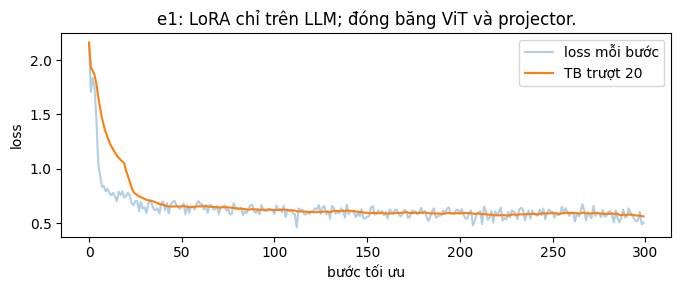

{'trainable_params': 33030144, 'peak_vram_gb': 6.35, 'train_minutes': 40.9}


Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

work/e1_val40.jsonl: đã có 0, còn 40 ảnh


  0%|          | 0/10 [00:00<?, ?it/s]

xong trong 2.4 phút
[val40] valid=0.975 F1=0.275
work/e1.jsonl: đã có 0, còn 311 ảnh


...

xong trong 17.2 phút
E1 [test] n=311 valid=0.990 P=0.278 R=0.280 F1=0.279 CI95=0.243-0.318 meanIoU=0.674 FP/img=1.36
   pothole  P=0.284 R=0.157 F1=0.202
   crack    P=0.179 R=0.258 F1=0.211
   manhole  P=0.753 R=0.411 F1=0.532

=== Huấn luyện e2: E1 + mở đầy đủ projector (visual.merger và visual.deepstack_merger_list).


Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

  ViT (patch embed + pos embed + 24 blocks)         306.2M
  projector: visual.merger                           27.3M
  projector: visual.deepstack_merger_list            81.8M
  LLM (language_model, gồm embedding)              4022.5M
LoRA modules: 252 (LLM 252, ViT 0)
Tham số huấn luyện: LoRA 33,030,144 + projector 109,105,152 = 142,135,296
Train: 1422 ảnh, 300 bước × 2×4 ảnh/bước


  0%|          | 0/300 [00:00<?, ?it/s]

  bước 100: loss TB 20 bước cuối = 0.6197, đã lưu work/e2/ckpt.pt
  bước 200: loss TB 20 bước cuối = 0.5261, đã lưu work/e2/ckpt.pt
  bước 300: loss TB 20 bước cuối = 0.5213, đã lưu work/e2/ckpt.pt


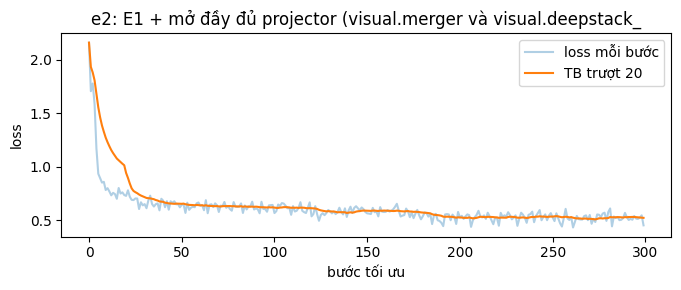

{'trainable_params': 142135296, 'peak_vram_gb': 8.05, 'train_minutes': 46.0}


Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

Đã nạp 24 tensor projector; |Δ| lớn nhất so với projector gốc = 0.0141 (>0 ⇒ đã thật sự huấn luyện)
work/e2_val40.jsonl: đã có 0, còn 40 ảnh


  0%|          | 0/10 [00:00<?, ?it/s]

xong trong 2.2 phút
[val40] valid=1.000 F1=0.480
work/e2.jsonl: đã có 0, còn 311 ảnh


...

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

  ViT (patch embed + pos embed + 24 blocks)         306.2M
  projector: visual.merger                           27.3M
  projector: visual.deepstack_merger_list            81.8M
  LLM (language_model, gồm embedding)              4022.5M
LoRA modules: 348 (LLM 252, ViT 96)
Tham số huấn luyện: LoRA 39,321,600 + projector 109,105,152 = 148,426,752
Train: 1422 ảnh, 300 bước × 2×4 ảnh/bước


  0%|          | 0/300 [00:00<?, ?it/s]

/tmp/ipykernel_1809/2374988769.py:58: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True); sched.step()


  bước 100: loss TB 20 bước cuối = 0.5978, đã lưu work/e3/ckpt.pt
  bước 200: loss TB 20 bước cuối = 0.4955, đã lưu work/e3/ckpt.pt
  bước 300: loss TB 20 bước cuối = 0.4985, đã lưu work/e3/ckpt.pt


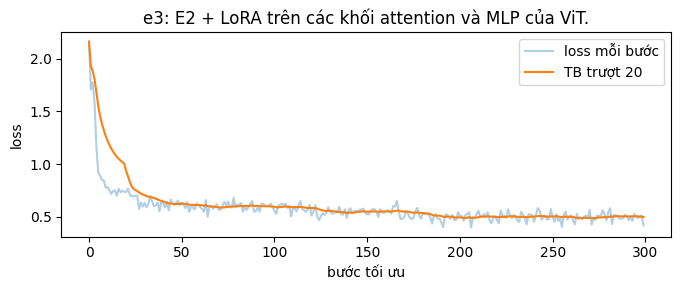

{'trainable_params': 148426752, 'peak_vram_gb': 8.22, 'train_minutes': 52.7}


Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

Đã nạp 24 tensor projector; |Δ| lớn nhất so với projector gốc = 0.0131 (>0 ⇒ đã thật sự huấn luyện)
work/e3_val40.jsonl: đã có 0, còn 40 ảnh


  0%|          | 0/10 [00:00<?, ?it/s]

xong trong 2.4 phút
[val40] valid=1.000 F1=0.481
work/e3.jsonl: đã có 0, còn 311 ảnh


  0%|          | 0/78 [00:00<?, ?it/s]

xong trong 15.2 phút
E3 [test] n=311 valid=1.000 P=0.437 R=0.401 F1=0.418 CI95=0.377-0.464 meanIoU=0.697 FP/img=0.97
   pothole  P=0.297 R=0.273 F1=0.284
   crack    P=0.339 R=0.341 F1=0.340
   manhole  P=0.798 R=0.607 F1=0.690



In [25]:
# Mỗi thí nghiệm ≈ 20–35 phút train + ~10 phút suy luận. Chạy lại ô này sau khi mất session: phần đã xong sẽ được bỏ qua.
results = {}
for key in ("e1", "e2", "e3"):
    results[key] = run_experiment(key, load_cfg(key))

In [26]:
# Bảng tổng hợp E0–E3 (dán vào REPORT.md) + kiểm tra tiêu chí tự động của rubric
SETUP = {"e0": "zero-shot", "e1": "LoRA LLM", "e2": "+ projector", "e3": "+ LoRA ViT"}

def table_row(key, setup):
    d = json.load(open(f"report/evidence/{key}.json", encoding="utf-8"))
    m, pc, meta = d["micro"], d["per_class"], d.get("meta", {})
    return (f"| {d['name']} | {setup} | {meta.get('trainable_params', 0):,} | {meta.get('peak_vram_gb', '')} | "
            f"{meta.get('train_minutes', '')} | {m['f1']:.3f} | [{d['f1_ci95'][0]:.3f}, {d['f1_ci95'][1]:.3f}] | "
            f"{d['fp_per_image']:.2f} | {pc['pothole']['f1']:.3f} | {pc['crack']['f1']:.3f} | {pc['manhole']['f1']:.3f} |")

print("| Mã | Setup | Tham số huấn luyện | VRAM đỉnh (GB) | Phút | F1 | CI95 | FP/ảnh | F1 pothole | F1 crack | F1 manhole |")
print("|---|---|---|---|---|---|---|---|---|---|---|")
for k, s in SETUP.items():
    print(table_row(k, s))

ev = {k: json.load(open(f"report/evidence/{k}.json", encoding="utf-8")) for k in SETUP}
print()
print("E1 parse_valid_rate ≥ 0.95:", "PASS" if ev["e1"]["parse_valid_rate"] >= 0.95 else "FAIL", ev["e1"]["parse_valid_rate"])
d = ev["e1"]["micro"]["f1"] - ev["e0"]["micro"]["f1"]
print("F1(E1) − F1(E0) ≥ 0.10:", "PASS" if d >= 0.10 else "FAIL", round(d, 3))
print("E2 − E1 tham số:", f"{ev['e2']['meta']['trainable_params'] - ev['e1']['meta']['trainable_params']:,}", "(kỳ vọng ≈ 109M)")
print("Cùng dataset_version:", {e["dataset_version"] for e in ev.values()} == {DATASET_VERSION})
if restore("work/param_breakdown.json") or Path("work/param_breakdown.json").exists():
    print("Phân rã tham số (câu 1):", json.load(open("work/param_breakdown.json")))

| Mã | Setup | Tham số huấn luyện | VRAM đỉnh (GB) | Phút | F1 | CI95 | FP/ảnh | F1 pothole | F1 crack | F1 manhole |
|---|---|---|---|---|---|---|---|---|---|---|
| E0 | zero-shot | 0 |  |  | 0.086 | [0.061, 0.113] | 0.92 | 0.107 | 0.032 | 0.178 |
| E1 | LoRA LLM | 33,030,144 | 6.35 | 40.9 | 0.279 | [0.243, 0.318] | 1.36 | 0.202 | 0.211 | 0.532 |
| E2 | + projector | 142,135,296 | 8.05 | 46.0 | 0.366 | [0.323, 0.411] | 0.97 | 0.192 | 0.316 | 0.600 |
| E3 | + LoRA ViT | 148,426,752 | 8.22 | 52.7 | 0.418 | [0.377, 0.464] | 0.97 | 0.284 | 0.340 | 0.690 |

E1 parse_valid_rate ≥ 0.95: PASS 0.9903536977491961
F1(E1) − F1(E0) ≥ 0.10: PASS 0.193
E2 − E1 tham số: 109,105,152 (kỳ vọng ≈ 109M)
Cùng dataset_version: True
Phân rã tham số (câu 1): {'ViT (patch embed + pos embed + 24 blocks)': 306242560, 'projector: visual.merger': 27271680, 'projector: visual.deepstack_merger_list': 81833472, 'LLM (language_model, gồm embedding)': 4022468096}


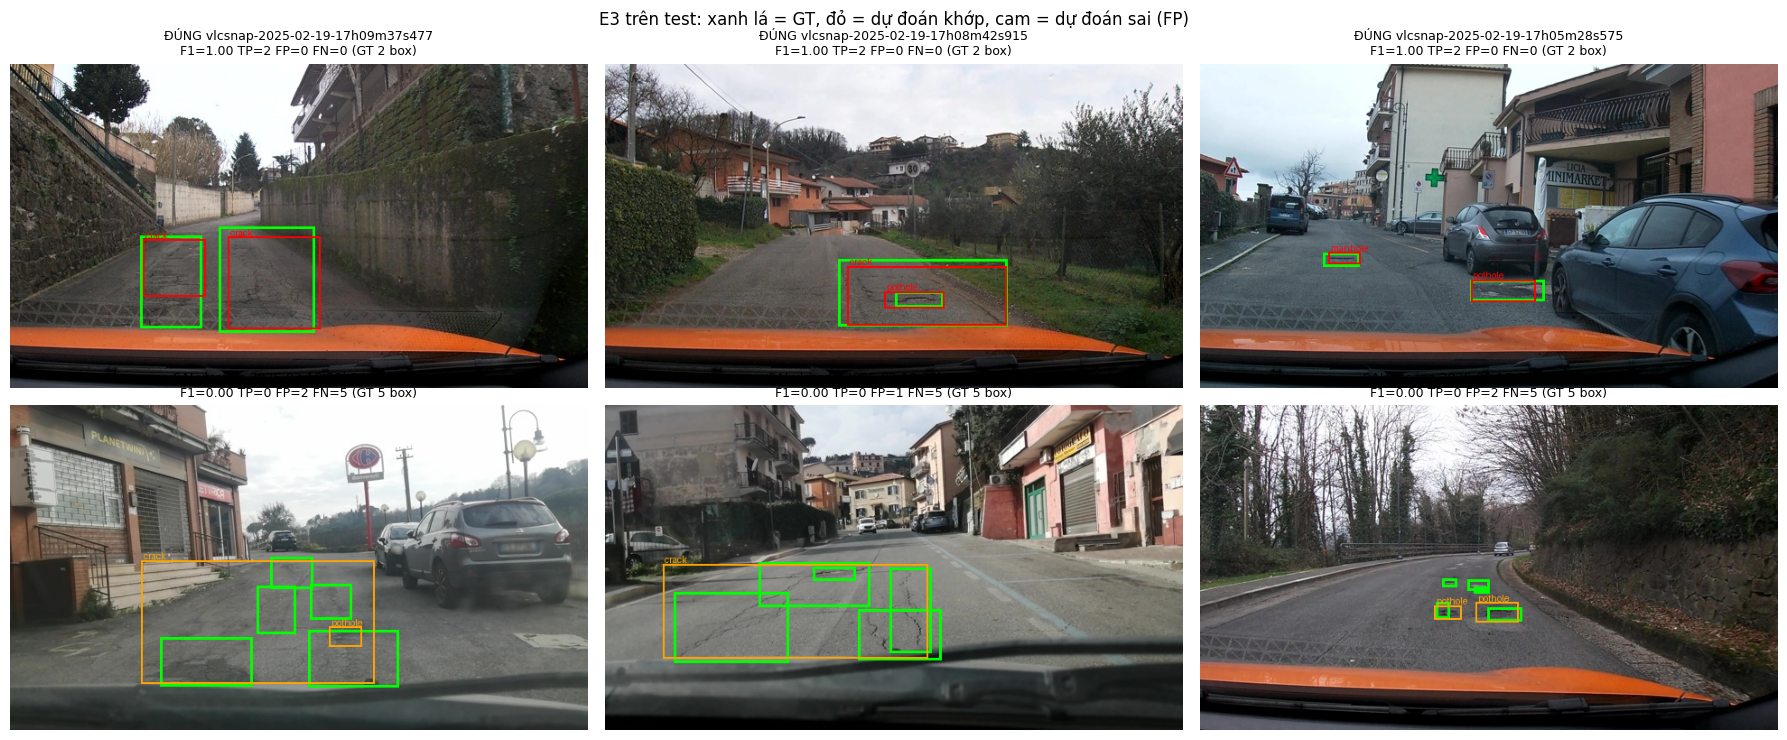

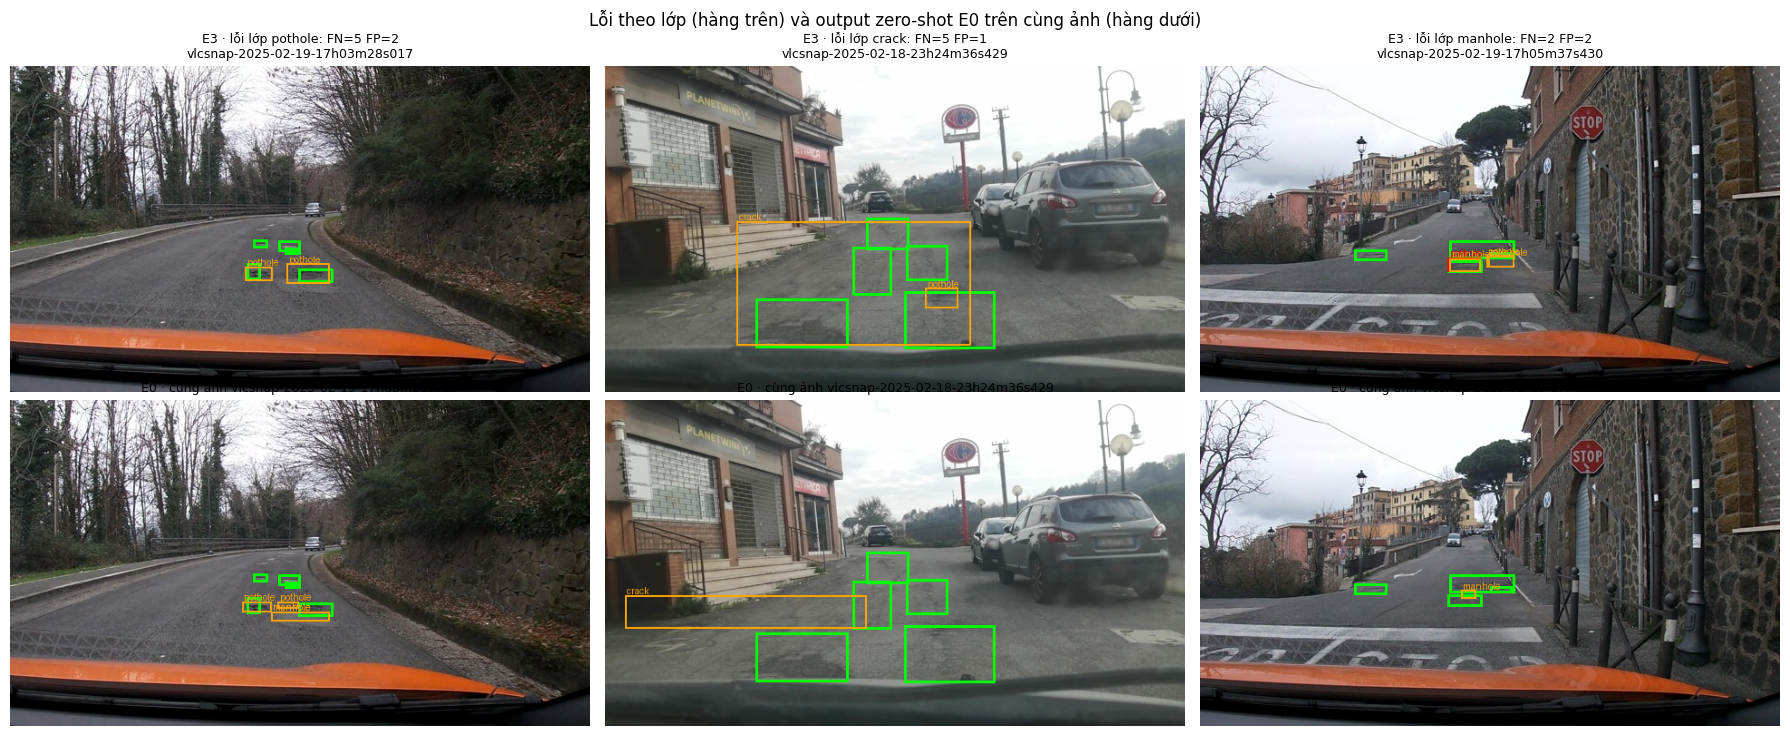

In [27]:
# Ảnh minh hoạ (rubric B, câu 9): GT = xanh lá, dự đoán = đỏ (khớp, IoU ≥ 0.5) / cam (không khớp = FP).
# 3 ảnh tốt nhất + 3 ảnh tệ nhất theo F1 từng ảnh của setup tốt nhất, và 1 ảnh lỗi tiêu biểu cho mỗi lớp.
from scripts.score import _gt_boxes, _match, iou_xyxy

VIZ_KEY = max(("e1", "e2", "e3"), key=lambda k: json.load(open(f"report/evidence/{k}.json", encoding="utf-8"))["micro"]["f1"])
restore(f"work/{VIZ_KEY}.jsonl"); restore("work/e0.jsonl")

def draw_pred(row, raw):
    img = load_image(row).copy()
    d = ImageDraw.Draw(img)
    W, H = img.size
    sx, sy = W / 1000, H / 1000
    gt = _gt_boxes(row)
    pred = parse_output(raw) or []
    for b in gt:
        x1, y1, x2, y2 = b["bbox"]
        d.rectangle((x1 * sx, y1 * sy, x2 * sx, y2 * sy), outline="lime", width=3)
    for p in pred:
        hit = any(g["label"] == p["label"] and iou_xyxy(g["bbox"], p["bbox"]) >= 0.5 for g in gt)
        x1, y1, x2, y2 = p["bbox"]
        d.rectangle((x1 * sx, y1 * sy, x2 * sx, y2 * sy), outline="red" if hit else "orange", width=2)
        d.text((x1 * sx + 2, max(0, y1 * sy - 11)), p["label"], fill="red" if hit else "orange")
    return img

def image_stats(key):
    preds = {r["image_id"]: r["raw"] for r in read_jsonl(f"work/{key}.jsonl")}
    out = []
    for e in data["test"]:
        per, _ = _match(_gt_boxes(e), parse_output(preds[e["image_id"]]) or [])
        tp, fp, fn = (sum(v[k] for v in per.values()) for k in range(3))
        f1 = 2 * tp / (2 * tp + fp + fn) if tp + fp + fn else 1.0
        out.append((f1, tp, fp, fn, per, e, preds[e["image_id"]]))
    return out

def grid(items, title, fname):
    fig, axes = plt.subplots(2, 3, figsize=(18, 7.5))
    for ax, (cap, row, raw) in zip(axes.flat, items):
        ax.imshow(draw_pred(row, raw)); ax.set_title(cap, fontsize=9); ax.axis("off")
    for ax in list(axes.flat)[len(items):]:
        ax.axis("off")
    fig.suptitle(title); plt.tight_layout()
    fig.savefig(f"report/figures/{fname}", dpi=80, bbox_inches="tight"); plt.show()
    backup(f"report/figures/{fname}")

st = [s for s in image_stats(VIZ_KEY) if s[5]["objects"]]          # chỉ ảnh có hư hại
st.sort(key=lambda s: (s[0], -len(s[5]["objects"])))
cap = lambda s, tag: f"{tag} {s[5]['image_id']}\nF1={s[0]:.2f} TP={s[1]} FP={s[2]} FN={s[3]} (GT {len(s[5]['objects'])} box)"
best3 = [s for s in reversed(st) if s[1] >= 2][:3] or st[-3:]
worst3 = st[:3]
grid([(cap(s, "ĐÚNG"), s[5], s[6]) for s in best3] + [(cap(s, "SAI"), s[5], s[6]) for s in worst3],
     f"{VIZ_KEY.upper()} trên test: xanh lá = GT, đỏ = dự đoán khớp, cam = dự đoán sai (FP)", "pred_examples.png")

# Mỗi lớp: ảnh có nhiều FN nhất của lớp đó (lỗi tiêu biểu theo lớp) + cùng ảnh đó ở E0
items = []
for c in CLASSES:
    s = max(st, key=lambda s: (s[4][c][2], s[4][c][1]))
    items.append((f"{VIZ_KEY.upper()} · lỗi lớp {c}: FN={s[4][c][2]} FP={s[4][c][1]}\n{s[5]['image_id']}", s[5], s[6]))
e0p = {r["image_id"]: r["raw"] for r in read_jsonl("work/e0.jsonl")}
for _, row, _ in list(items):
    items.append((f"E0 · cùng ảnh {row['image_id']}", row, e0p[row["image_id"]]))
grid(items, "Lỗi theo lớp (hàng trên) và output zero-shot E0 trên cùng ảnh (hàng dưới)", "per_class_errors.png")

## 8. E4 (ablation tự chọn) và E5 (tuỳ chọn, GRPO)

### E4: ablation — đổi **đúng một** biến so với setup tốt nhất của E1–E3

Đổi `E4_VARIABLE` để chọn biến. Giá trị nào trùng setup gốc (`data_size=1.0`, `coord_scale=norm1000`) thì **dùng lại**
predictions của setup gốc (không train lại), chỉ chấm lại dưới tên E4.

Setup gốc: e3 (F1 test 0.418) | biến: data_size = [0.1, 1.0] (train_fraction; 0.1 = 10% số ảnh train)

######## e4_data_0.1
=== Huấn luyện e4_data_0.1: E4 data_size=0.1 (gốc e3)


Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

  ViT (patch embed + pos embed + 24 blocks)         306.2M
  projector: visual.merger                           27.3M
  projector: visual.deepstack_merger_list            81.8M
  LLM (language_model, gồm embedding)              4022.5M
LoRA modules: 348 (LLM 252, ViT 96)
Tham số huấn luyện: LoRA 39,321,600 + projector 109,105,152 = 148,426,752
Train: 142 ảnh, 300 bước × 2×4 ảnh/bước


  0%|          | 0/300 [00:00<?, ?it/s]

  bước 100: loss TB 20 bước cuối = 0.4492, đã lưu work/e4_data_0.1/ckpt.pt
  bước 200: loss TB 20 bước cuối = 0.1535, đã lưu work/e4_data_0.1/ckpt.pt
  bước 300: loss TB 20 bước cuối = 0.0054, đã lưu work/e4_data_0.1/ckpt.pt


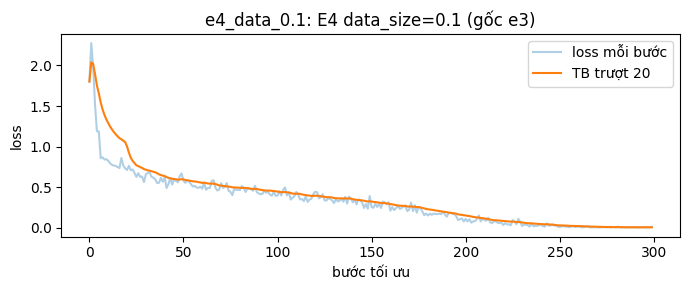

{'trainable_params': 148426752, 'peak_vram_gb': 7.67, 'train_minutes': 53.3}


Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

Đã nạp 24 tensor projector; |Δ| lớn nhất so với projector gốc = 0.0141 (>0 ⇒ đã thật sự huấn luyện)
work/e4_data_0.1_val40.jsonl: đã có 0, còn 40 ảnh


  0%|          | 0/10 [00:00<?, ?it/s]

xong trong 3.2 phút
[val40] valid=1.000 F1=0.369
work/e4_data_0.1.jsonl: đã có 0, còn 311 ảnh


  0%|          | 0/78 [00:00<?, ?it/s]

xong trong 18.8 phút
e4_data_0.1 [test] n=311 valid=0.994 P=0.243 R=0.297 F1=0.267 CI95=0.235-0.303 meanIoU=0.670 FP/img=1.73
   pothole  P=0.180 R=0.248 F1=0.208
   crack    P=0.156 R=0.224 F1=0.184
   manhole  P=0.661 R=0.466 F1=0.547


######## e4_data_1.0
e4_data_1.0 [test] n=311 valid=1.000 P=0.437 R=0.401 F1=0.418 CI95=0.377-0.464 meanIoU=0.697 FP/img=0.97
   pothole  P=0.297 R=0.273 F1=0.284
   crack    P=0.339 R=0.341 F1=0.340
   manhole  P=0.798 R=0.607 F1=0.690



In [28]:
import copy, shutil

E4_VARIABLE = "data_size"      # "data_size" | "rank" | "coord_scale"
BEST = None                    # None → setup có F1 test cao nhất trong E1–E3; hoặc đặt "e1"/"e2"/"e3"

PROMPT_PIXEL = (
    "Locate road damage in this image. "
    "Detect only objects of classes: pothole, crack, manhole. "
    "Output a JSON list of objects with label and bbox_2d coordinates "
    "in absolute pixels of the 640x360 image: "
    '[{"label": "...", "bbox_2d": [x1, y1, x2, y2]}]. '
    "If no damage is found, output []."
)

f1_of = lambda k: json.load(open(f"report/evidence/{k}.json", encoding="utf-8"))["micro"]["f1"]
best = BEST or max(("e1", "e2", "e3"), key=f1_of)
base_cfg = load_cfg(best)
opt = load_cfg("e4")["options"][E4_VARIABLE]
print(f"Setup gốc: {best} (F1 test {f1_of(best):.3f}) | biến: {E4_VARIABLE} = {opt['values']} ({opt['note']})")

def e4_key(v):
    return {"data_size": f"e4_data_{v}", "rank": f"e4_rank_{v}", "coord_scale": f"e4_coord_{v}"}[E4_VARIABLE]

def reuse_base(key, coord="norm1000"):
    """Giá trị này chính là setup gốc → chấm lại predictions của setup gốc dưới tên E4 (meta của lần train gốc)."""
    restore(f"report/evidence/{key}.json")
    if Path(f"report/evidence/{key}.json").exists():
        return json.load(open(f"report/evidence/{key}.json", encoding="utf-8"))
    restore(f"work/{best}/run.json"); restore(f"work/{best}.jsonl")
    shutil.copy(f"work/{best}.jsonl", f"work/{key}.jsonl")
    run = json.load(open(f"work/{best}/run.json"))
    return score(key, key, coord=coord, meta={k: run[k] for k in ("trainable_params", "peak_vram_gb", "train_minutes")})

E4_KEYS = []
for v in opt["values"]:
    key = e4_key(v)
    E4_KEYS.append(key)
    cfg = copy.deepcopy(base_cfg)
    cfg["description"] = f"E4 {E4_VARIABLE}={v} (gốc {best})"
    print(f"\n######## {key}")
    if E4_VARIABLE == "data_size":
        if v == 1.0:
            results[key] = reuse_base(key)
        else:
            results[key] = run_experiment(key, cfg, fraction=v)
    elif E4_VARIABLE == "rank":
        cfg["lora"]["r"], cfg["lora"]["alpha"] = v, 2 * v
        if (v, 2 * v) == (base_cfg["lora"]["r"], base_cfg["lora"]["alpha"]):
            results[key] = reuse_base(key)
        else:
            results[key] = run_experiment(key, cfg)
    elif E4_VARIABLE == "coord_scale":
        if v == "norm1000":
            results[key] = reuse_base(key)
        else:   # đổi CẢ nhãn, prompt và cách chấm
            results[key] = run_experiment(key, cfg, prompt=PROMPT_PIXEL, answer_fn=objects_to_answer_pixel, coord="pixel")

In [29]:
# So sánh có ghép cặp (paired bootstrap): cùng một tập ảnh được lấy mẫu lại cho cả hai setup,
# nên khoảng tin cậy của ΔF1 hẹp hơn so với chỉ nhìn hai CI95 riêng lẻ có chồng nhau hay không.
from scripts.score import _gt_boxes, _match, _prf, _to_norm1000

def per_image_counts(key):
    d = json.load(open(f"report/evidence/{key}.json", encoding="utf-8"))
    restore(f"work/{key}.jsonl")
    preds = {r["image_id"]: r["raw"] for r in read_jsonl(f"work/{key}.jsonl")}
    rows = []
    for e in data["test"]:
        p = parse_output(preds.get(e["image_id"]))
        p = _to_norm1000(p, d["coord"], e["width"], e["height"]) if p is not None else []
        per, _ = _match(_gt_boxes(e), p)
        rows.append([sum(v[k] for v in per.values()) for k in range(3)])
    return rows

def paired_delta(key_a, key_b, n_boot=2000, seed=0):
    a, b = per_image_counts(key_a), per_image_counts(key_b)
    f1 = lambda rows, idx: _prf(*(sum(rows[i][k] for i in idx) for k in range(3)))["f1"]
    full = list(range(len(a)))
    delta = f1(b, full) - f1(a, full)
    rng, ds = random.Random(seed), []
    for _ in range(n_boot):
        idx = [rng.randrange(len(a)) for _ in full]
        ds.append(f1(b, idx) - f1(a, idx))
    ds.sort()
    lo, hi = ds[int(0.025 * n_boot)], ds[int(0.975 * n_boot) - 1]
    verdict = "khác biệt có ý nghĩa" if lo > 0 or hi < 0 else "CHƯA đủ bằng chứng (CI chứa 0)"
    print(f"F1({key_b}) − F1({key_a}) = {delta:+.3f}, CI95 ghép cặp [{lo:+.3f}, {hi:+.3f}] → {verdict}")
    return delta, (lo, hi)

def ci_overlap(key_a, key_b):
    ca = json.load(open(f"report/evidence/{key_a}.json", encoding="utf-8"))["f1_ci95"]
    cb = json.load(open(f"report/evidence/{key_b}.json", encoding="utf-8"))["f1_ci95"]
    ov = max(ca[0], cb[0]) <= min(ca[1], cb[1])
    print(f"CI95 {key_a} [{ca[0]:.3f}, {ca[1]:.3f}] vs {key_b} [{cb[0]:.3f}, {cb[1]:.3f}] → "
          f"{'CHỒNG NHAU' if ov else 'tách rời'} (độ rộng {ca[1] - ca[0]:.3f} / {cb[1] - cb[0]:.3f})")

print("| Mã | Setup | Tham số huấn luyện | VRAM đỉnh (GB) | Phút | F1 | CI95 | FP/ảnh | F1 pothole | F1 crack | F1 manhole |")
print("|---|---|---|---|---|---|---|---|---|---|---|")
for k in E4_KEYS:
    print(table_row(k, k.replace("e4_", "").replace("_", "=", 1)))
print()
print("== E4 (câu 10)")
ci_overlap(*E4_KEYS)
paired_delta(*E4_KEYS)
print("\n== E0–E3 (câu 7, 8)")
for a, b in (("e0", "e1"), ("e1", "e2"), ("e2", "e3"), ("e1", "e3")):
    ci_overlap(a, b)
    paired_delta(a, b)

| Mã | Setup | Tham số huấn luyện | VRAM đỉnh (GB) | Phút | F1 | CI95 | FP/ảnh | F1 pothole | F1 crack | F1 manhole |
|---|---|---|---|---|---|---|---|---|---|---|
| e4_data_0.1 | data=0.1 | 148,426,752 | 7.67 | 53.3 | 0.267 | [0.235, 0.303] | 1.73 | 0.208 | 0.184 | 0.547 |
| e4_data_1.0 | data=1.0 | 148,426,752 | 8.22 | 52.7 | 0.418 | [0.377, 0.464] | 0.97 | 0.284 | 0.340 | 0.690 |

== E4 (câu 10)
CI95 e4_data_0.1 [0.235, 0.303] vs e4_data_1.0 [0.377, 0.464] → tách rời (độ rộng 0.068 / 0.087)
F1(e4_data_1.0) − F1(e4_data_0.1) = +0.151, CI95 ghép cặp [+0.110, +0.194] → khác biệt có ý nghĩa

== E0–E3 (câu 7, 8)
CI95 e0 [0.061, 0.113] vs e1 [0.243, 0.318] → tách rời (độ rộng 0.051 / 0.075)
F1(e1) − F1(e0) = +0.193, CI95 ghép cặp [+0.155, +0.232] → khác biệt có ý nghĩa
CI95 e1 [0.243, 0.318] vs e2 [0.323, 0.411] → tách rời (độ rộng 0.075 / 0.088)
F1(e2) − F1(e1) = +0.087, CI95 ghép cặp [+0.050, +0.126] → khác biệt có ý nghĩa
CI95 e2 [0.323, 0.411] vs e3 [0.377, 0.464] → CHỒNG NHAU (độ rộn

### E5 (tuỳ chọn, +10): GRPO với reward IoU

Hàm reward ở `lab/reward.py`, test ở `lab/test_reward.py` (Python thuần, chạy **trước** khi huấn luyện).
Khởi tạo từ adapter của setup tốt nhất E1–E3 (`best`, cùng setup gốc của E4); chỉ cập nhật LoRA, projector (nếu có) giữ nguyên bản đã SFT.
Đặt `RUN_E5 = False` để bỏ qua.

In [30]:
RUN_E5 = True
!python -m pytest lab -q

...........                                                              [100%]
11 passed in 0.04s


In [31]:
# GRPO bằng trl==1.9.2. Những chỗ phải khác mặc định của trl:
#  - fp16=True, bf16=False: trl mặc định bf16 khi fp16 không đặt; T4 không có bf16 nhanh.
#  - remove_unused_columns=False: nếu không, trl xoá cột "gt" trước khi gọi hàm reward.
#  - trl ép tham số huấn luyện của model lượng tử về bf16 → đưa lại fp32 (lr 5e-6: cập nhật nhỏ hơn
#    độ phân giải của bf16 ~8e-3 tương đối, sẽ bị làm tròn mất), và GradScaler của fp16 cần master weight fp32.
#  - beta=0.0 (configs/e5.yaml): không cần model tham chiếu → không tốn thêm VRAM.
from datasets import Dataset as HFDataset, Image as HFImage
from trl import GRPOConfig, GRPOTrainer
from lab.reward import compute_reward, iou_reward
from scripts.score import _gt_boxes

e5_cfg = load_cfg("e5")
g5 = e5_cfg["grpo"]
E5_DIR = Path("work/e5")
best_has_projector = load_cfg(best)["train_projector"]

def load_with_adapter(adapter_dir, projector_path=None, trainable=False):
    model, _ = load_base_model()
    model = PeftModel.from_pretrained(model, str(adapter_dir), is_trainable=trainable)
    if projector_path:
        restore(str(projector_path))
        proj = torch.load(projector_path, map_location="cpu")
        by_name = dict(model.named_parameters())
        for n, v in proj.items():
            by_name[n].data.copy_(v)
            by_name[n].requires_grad = False      # GRPO chỉ cập nhật LoRA
        print(f"Đã nạp projector SFT ({len(proj)} tensor) từ {projector_path}")
    return model

def make_grpo_dataset(rows):
    return HFDataset.from_dict({
        "prompt": [[{"role": "user", "content": PROMPT}] for _ in rows],     # trl tự chèn ảnh vào hội thoại
        "image": [str(Path("data") / r["image_path"]) for r in rows],
        "gt": [json.dumps([{"label": b["label"], "bbox": list(b["bbox"])} for b in _gt_boxes(r)]) for r in rows],
    }).cast_column("image", HFImage())

if RUN_E5:
    for f in ("adapter", "run.json", "log.json"):
        restore(str(E5_DIR / f))
    restore(f"work/{best}/adapter")
    if not (E5_DIR / "run.json").exists():
        model = load_with_adapter(f"work/{best}/adapter",
                                  f"work/{best}/projector.pt" if best_has_projector else None, trainable=True)
        # Bỏ ảnh có đáp án dài hơn max_completion_length (128 token): completion chắc chắn bị cắt → reward 0 vô nghĩa
        rows = [r for r in data["train"]
                if len(processor.tokenizer(objects_to_answer(r["objects"]))["input_ids"]) < g5["max_completion_length"] - 8]
        print(f"GRPO dùng {len(rows)}/{len(data['train'])} ảnh train (đáp án < {g5['max_completion_length'] - 8} token)")
        rows = random.Random(42).sample(rows, len(rows))
        grpo_args = GRPOConfig(
            output_dir=str(E5_DIR / "trainer"), max_steps=g5["max_steps"], learning_rate=g5["learning_rate"],
            beta=g5["beta"], num_generations=g5["num_generations"], max_completion_length=g5["max_completion_length"],
            per_device_train_batch_size=4, gradient_accumulation_steps=2,   # mỗi bước: 2 ảnh × 4 completion
            temperature=1.0, use_vllm=False, fp16=True, bf16=False,
            gradient_checkpointing=True, gradient_checkpointing_kwargs={"use_reentrant": False},
            remove_unused_columns=False, logging_steps=1, save_strategy="no", report_to="none",
            log_completions=False, seed=42, dataloader_num_workers=0)
        trainer = GRPOTrainer(model=model, reward_funcs=iou_reward, args=grpo_args,
                              train_dataset=make_grpo_dataset(rows), processing_class=processor)
        for p in trainer.model.parameters():
            if p.requires_grad:
                p.data = p.data.float()
        n_train = sum(p.numel() for p in trainer.model.parameters() if p.requires_grad)
        print(f"Tham số huấn luyện GRPO: {n_train:,}")
        torch.cuda.reset_peak_memory_stats()
        t0 = time.time()
        trainer.train()
        run5 = {"trainable_params": n_train, "peak_vram_gb": round(torch.cuda.max_memory_allocated() / 2**30, 2),
                "train_minutes": round((time.time() - t0) / 60, 1), "init_from": best}
        trainer.model.save_pretrained(E5_DIR / "adapter")
        json.dump(trainer.state.log_history, open(E5_DIR / "log.json", "w"), indent=1)
        json.dump(run5, open(E5_DIR / "run.json", "w"), indent=1)
        for f in ("adapter", "run.json", "log.json"):
            backup(str(E5_DIR / f))
        print(run5)
        del trainer, model
        gc.collect(); torch.cuda.empty_cache()

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

Đã nạp projector SFT (24 tensor) từ work/e3/projector.pt
GRPO dùng 1280/1422 ảnh train (đáp án < 120 token)


[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'pad_token_id': 151643}.


Tham số huấn luyện GRPO: 39,321,600


Step,Training Loss
1,-0.041834
2,0.119565
3,0.184157
4,-0.113876
5,0.085205
6,0.303768
7,0.217061
8,0.053729
9,-0.060106
10,0.263035


{'trainable_params': 39321600, 'peak_vram_gb': 5.65, 'train_minutes': 27.7, 'init_from': 'e3'}


Các chỉ số có trong log: ['clip_ratio/high_max', 'clip_ratio/high_mean', 'clip_ratio/low_mean', 'clip_ratio/low_min', 'clip_ratio/region_mean', 'completions/clipped_ratio', 'completions/max_length', 'completions/max_terminated_length', 'completions/mean_length', 'completions/mean_terminated_length', 'completions/min_length', 'completions/min_terminated_length', 'entropy', 'epoch', 'frac_reward_zero_std', 'grad_norm', 'learning_rate', 'loss', 'num_tokens', 'reward', 'reward_std', 'rewards/iou_reward/mean', 'rewards/iou_reward/std', 'step', 'step_time']


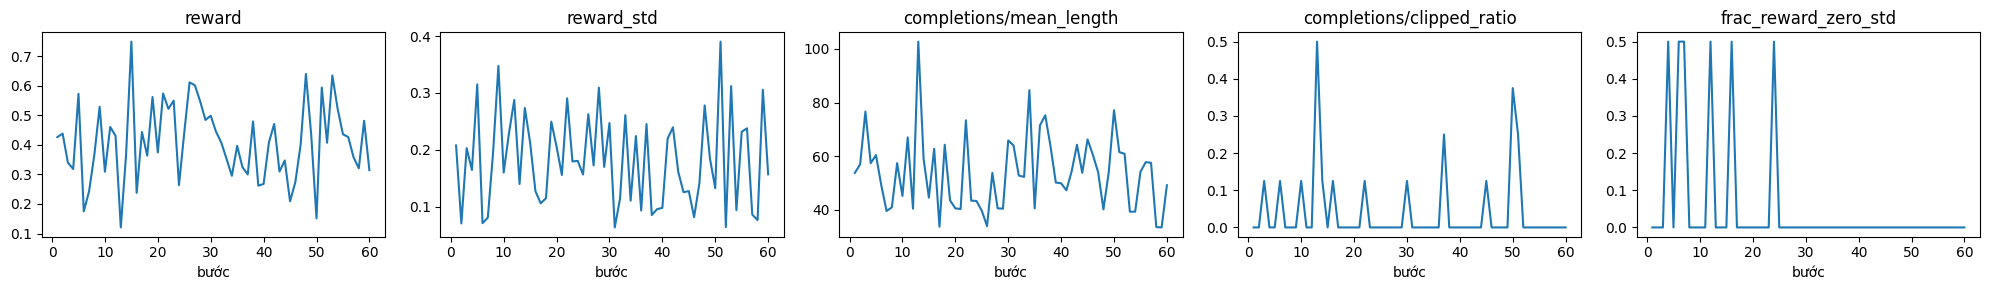

{'reward': 0.4259, 'reward_std': 0.2075, 'completions/mean_length': 53.75, 'completions/clipped_ratio': 0.0, 'frac_reward_zero_std': 0.0} step 1
{'reward': 0.438, 'reward_std': 0.0702, 'completions/mean_length': 56.875, 'completions/clipped_ratio': 0.0, 'frac_reward_zero_std': 0.0} step 2
{'reward': 0.3398, 'reward_std': 0.2028, 'completions/mean_length': 76.625, 'completions/clipped_ratio': 0.125, 'frac_reward_zero_std': 0.0} step 3
{'reward': 0.3204, 'reward_std': 0.0761, 'completions/mean_length': 33.5, 'completions/clipped_ratio': 0.0, 'frac_reward_zero_std': 0.0} step 58
{'reward': 0.4813, 'reward_std': 0.3056, 'completions/mean_length': 33.375, 'completions/clipped_ratio': 0.0, 'frac_reward_zero_std': 0.0} step 59
{'reward': 0.3143, 'reward_std': 0.1567, 'completions/mean_length': 49.125, 'completions/clipped_ratio': 0.0, 'frac_reward_zero_std': 0.0} step 60


In [32]:
# Nhật ký GRPO: reward trung bình, độ lệch trong nhóm, độ dài completion (dấu hiệu reward hacking: độ dài sụt về ~2 token = "[]")
if RUN_E5:
    log = [r for r in json.load(open(E5_DIR / "log.json")) if "reward" in r]
    keys = [k for k in ("reward", "reward_std", "completions/mean_length", "completions/clipped_ratio",
                        "frac_reward_zero_std") if k in log[0]]
    print("Các chỉ số có trong log:", sorted(log[0]))
    fig, axes = plt.subplots(1, len(keys), figsize=(4 * len(keys), 3))
    for ax, k in zip(axes, keys):
        ax.plot([r["step"] for r in log], [r[k] for r in log]); ax.set_title(k); ax.set_xlabel("bước")
    plt.tight_layout(); plt.savefig("report/figures/grpo_log.png", dpi=80); plt.show()
    backup("report/figures/grpo_log.png")
    for r in log[:3] + log[-3:]:
        print({k: round(r[k], 4) for k in keys}, "step", r["step"])

In [ ]:
# Suy luận + chấm E5, so với SFT (setup gốc) bằng CI95 và paired bootstrap
if RUN_E5:
    restore("report/evidence/e5.json")
    if not Path("report/evidence/e5.json").exists():
        model = load_with_adapter(E5_DIR / "adapter", f"work/{best}/projector.pt" if best_has_projector else None)
        model.eval()
        run_inference(model, processor, data["test"], "work/e5.jsonl")
        del model
        gc.collect(); torch.cuda.empty_cache()
        run5 = json.load(open(E5_DIR / "run.json"))
        score("e5", "E5", meta={k: run5[k] for k in ("trainable_params", "peak_vram_gb", "train_minutes")})
    print(table_row(best, f"SFT ({best})"))
    print(table_row("e5", f"GRPO từ {best}"))
    ci_overlap(best, "e5")
    paired_delta(best, "e5")

    # Dấu hiệu reward hacking: tỉ lệ trả [], số box/ảnh, box khổng lồ, reward trung bình trên test
    gt_test = {r["image_id"]: r for r in data["test"]}
    def hacking_stats(key):
        preds = read_jsonl(f"work/{key}.jsonl")
        parsed = [parse_output(p["raw"]) for p in preds]
        ok = [x for x in parsed if x is not None]
        boxes = [b for x in ok for b in x]
        area = lambda b: (b["bbox"][2] - b["bbox"][0]) * (b["bbox"][3] - b["bbox"][1]) / 1e6
        rew = [compute_reward(p["raw"], _gt_boxes(gt_test[p["image_id"]])) for p in preds]
        n_gt_empty = sum(1 for r in data["test"] if not r["objects"])
        print(f"{key:>4s}: trả [] {sum(1 for x in ok if not x)}/{len(preds)} ảnh (GT rỗng: {n_gt_empty}) | "
              f"box/ảnh {len(boxes) / len(preds):.2f} (GT {sum(len(r['objects']) for r in data['test']) / len(preds):.2f}) | "
              f"box > 25% khung: {sum(area(b) > .25 for b in boxes)} | "
              f"diện tích box trung vị {100 * statistics.median([area(b) for b in boxes] or [0]):.2f}% | "
              f"reward TB {sum(rew) / len(rew):.3f}")
    hacking_stats(best)
    hacking_stats("e5")

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

Đã nạp projector SFT (24 tensor) từ work/e3/projector.pt
work/e5.jsonl: đã có 0, còn 311 ảnh


  0%|          | 0/78 [00:00<?, ?it/s]

## 9. Gom kết quả để nộp

Tải `report_results.zip` về, giải nén **đè lên thư mục repo trên máy** (chỉ chứa `report/evidence/*.json`, `report/figures/*.png`),
rồi điền `REPORT.md`, chạy `python scripts/check_submission.py` và commit. Không đưa `work/`, `data/` hay trọng số vào repo.

In [ ]:
import zipfile
files = sorted(list(Path("report/evidence").glob("*.json")) + list(Path("report/figures").glob("*.png")))
with zipfile.ZipFile("report_results.zip", "w") as z:
    for f in files:
        z.write(f)
        backup(str(f))
shutil.copy("report_results.zip", DRIVE_DIR / "report_results.zip")
print("\n".join(map(str, files)))
print("Đã lưu:", DRIVE_DIR / "report_results.zip")
!python scripts/check_submission.py
try:
    from google.colab import files as colab_files
    colab_files.download("report_results.zip")
except Exception as e:
    print("Tự tải từ Drive:", e)